# Analisis exploratorio de datos
### Librerías y unión de bases limpias

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Rutas a los archivos generados en la Etapa 2
carpeta_datos = Path("datos_procesados")

limpios = pd.read_csv(carpeta_datos / "anuncios_limpios.csv",
                      dtype={"id": "string", "host_id": "string"})
codificados = pd.read_csv(carpeta_datos / "anuncios_con_precio_codificados.csv",
                          dtype={"id": "string", "host_id": "string"})

# Unimos el precio por noche a la tabla limpia para el EDA
df = limpios.merge(codificados[["id", "precio_noche_usd"]], on="id", how="left")
df_precio = df.dropna(subset=["precio_noche_usd"]).copy()

print(f"Total anuncios: {len(df):,} | Con precio publicado: {len(df_precio):,}")
display(df_precio.head())

Total anuncios: 13,253 | Con precio publicado: 11,614


,id,host_id,barrio,tipo_habitacion,tipo_propiedad,banos,privacidad_bano,servicios_declarados,declara_wifi,declara_cocina,...,dias_disponibles_365,n_resenas,habitaciones,camas,noches_minimas,habitaciones_imputado,camas_imputado,banos_imputado,noches_minimas_imputado,precio_noche_usd
0,6,29,north hills,entire home/apt,entire home,2.0,sin_especificar,79,1,1,...,248,266,3,6,2,0,0,0,0,316.00
1,12447,48669,pacific beach,private room,private room in condo,1.0,privado,27,1,1,...,342,14,1,1,6,0,1,0,0,146.50
2,62274,302986,pacific beach,private room,private room in home,1.0,privado,34,1,0,...,193,1047,1,1,1,0,0,0,0,121.00
4,723387,3736562,pacific beach,entire home/apt,entire cottage,1.0,sin_especificar,52,1,1,...,309,202,1,1,1,0,0,0,0,282.00
5,741131,1291828,linda vista,entire home/apt,entire loft,1.0,sin_especificar,37,1,1,...,337,59,1,1,31,0,0,0,0,104.98


### Estadísticas descriptivas y verificación de atributos (Univariado)
Calculamos medidas de tendencia central, dispersión, asimetría y curtosis usando las funciones de resumen de Pandas.

In [2]:
num_cols = [
    "precio_noche_usd", "capacidad", "habitaciones", "camas", "banos",
    "servicios_declarados", "noches_minimas", "dias_disponibles_365", "n_resenas"
]

resumen = df_precio[num_cols].describe().T
resumen["asimetria"] = df_precio[num_cols].skew()
resumen["curtosis"] = df_precio[num_cols].kurt()
display(resumen[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "asimetria", "curtosis"]].round(2))

# Calificación únicamente sobre anuncios que sí tienen calificación
calif_validas = df.loc[df["tiene_calificacion"] == 1, "calificacion"]
print("Resumen de calificaciones (anuncios calificados):")
display(calif_validas.describe().to_frame().T.round(2))

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
precio_noche_usd,11614.0,379.52,402.91,18.78,162.34,270.38,463.67,9863.0,6.75,99.34
capacidad,11614.0,5.27,3.43,1.00,2.00,4.00,7.00,16.0,1.23,1.27
habitaciones,11614.0,1.99,1.44,0.00,1.00,2.00,3.00,32.0,2.21,20.47
camas,11614.0,2.93,2.41,1.00,1.00,2.00,4.00,37.0,3.48,26.43
banos,11614.0,1.68,1.05,0.00,1.00,1.00,2.00,23.0,3.06,25.58
servicios_declarados,11614.0,45.92,16.99,0.00,34.00,47.00,58.00,110.0,-0.18,-0.33
noches_minimas,11614.0,9.88,16.14,1.00,2.00,2.00,30.00,365.0,6.68,113.84
dias_disponibles_365,11614.0,235.25,109.17,0.00,150.00,264.00,332.00,365.0,-0.59,-0.94
n_resenas,11614.0,79.08,124.73,0.00,3.00,30.00,101.00,1918.0,3.39,20.12


Resumen de calificaciones (anuncios calificados):


,count,mean,std,min,25%,50%,75%,max
calificacion,11099.0,4.81,0.33,1.0,4.77,4.9,4.98,5.0


Esta tabla resume el comportamiento numérico de los 11.614 anuncios con precio publicado y los 11.099 con calificación, evidenciando la presencia de valores extremos y asimetrías

### Distribuciones univariadas: Histogramas con subplots
Visualizamos la distribución del precio (en escala normal y logarítmica para mitigar la asimetría), la capacidad y las calificaciones.

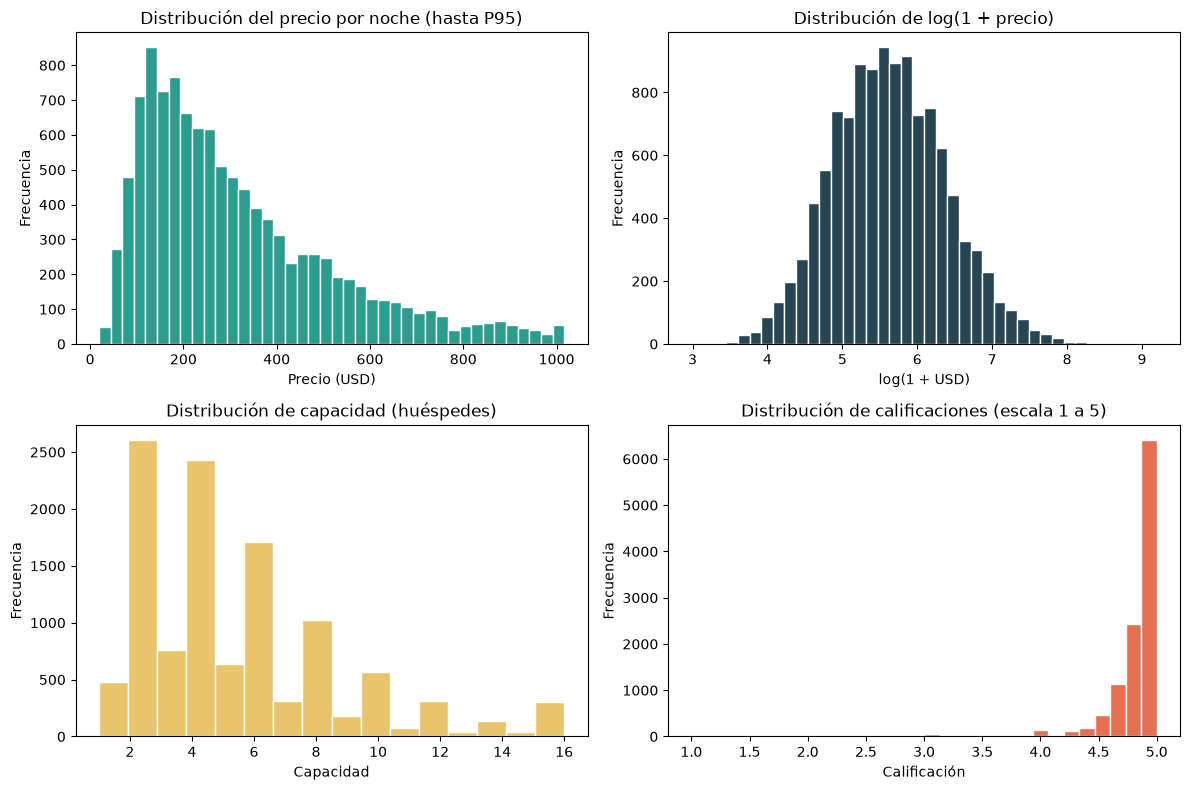

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# 1. Precio recortado al percentil 95 para ver la forma principal
p95 = df_precio["precio_noche_usd"].quantile(0.95)
ax[0, 0].hist(df_precio.loc[df_precio["precio_noche_usd"] <= p95, "precio_noche_usd"],
              bins=40, color="#2a9d8f", edgecolor="white")
ax[0, 0].set_title("Distribución del precio por noche (hasta P95)")
ax[0, 0].set_xlabel("Precio (USD)")
ax[0, 0].set_ylabel("Frecuencia")

# 2. Logaritmo del precio (útil para el modelo de regresión)
ax[0, 1].hist(np.log1p(df_precio["precio_noche_usd"]), bins=40, color="#264653", edgecolor="white")
ax[0, 1].set_title("Distribución de log(1 + precio)")
ax[0, 1].set_xlabel("log(1 + USD)")
ax[0, 1].set_ylabel("Frecuencia")

# 3. Capacidad de huéspedes
ax[1, 0].hist(df_precio["capacidad"], bins=16, color="#e9c46a", edgecolor="white")
ax[1, 0].set_title("Distribución de capacidad (huéspedes)")
ax[1, 0].set_xlabel("Capacidad")
ax[1, 0].set_ylabel("Frecuencia")

# 4. Calificaciones (solo anuncios con calificación)
ax[1, 1].hist(calif_validas, bins=30, color="#e76f51", edgecolor="white")
ax[1, 1].set_title("Distribución de calificaciones (escala 1 a 5)")
ax[1, 1].set_xlabel("Calificación")
ax[1, 1].set_ylabel("Frecuencia")

fig.tight_layout()
plt.show()

Los cuatro histogramas confirman visualmente las propiedades estadísticas vistas en las celdas anteriores.

### Análisis bivariado: Diagramas de violín y caja por tipo de habitación y superanfitrión
Comparamos la densidad y dispersión del precio según el tipo de alojamiento y si el anfitrión es Superhost.

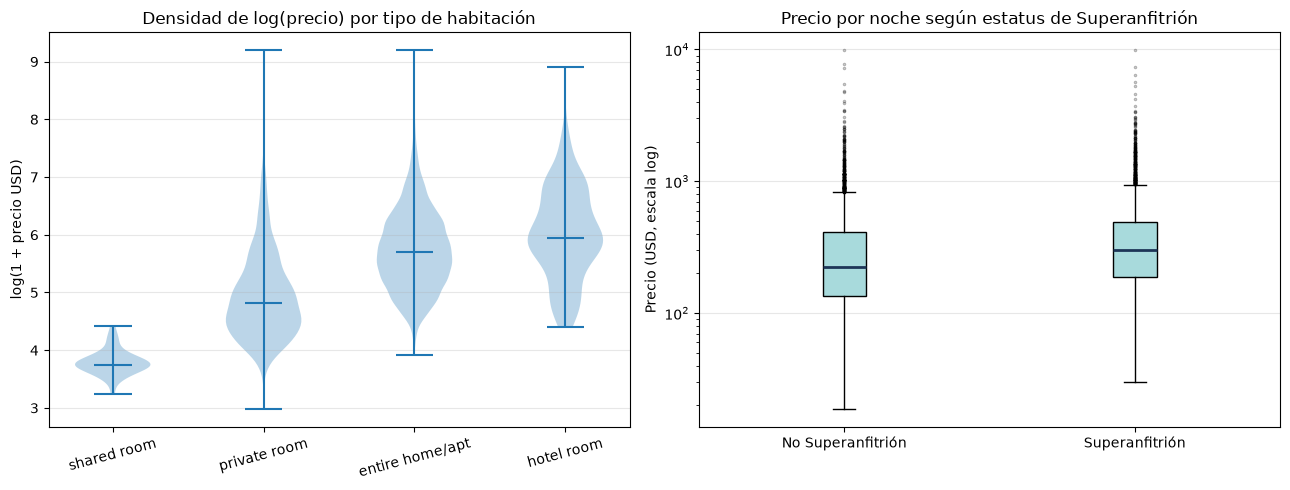

,count,median,mean
tipo_habitacion,,,
entire home/apt,9764,296.0,403.89
hotel room,267,382.0,569.54
private room,1541,122.0,201.37
shared room,42,41.6,44.31


,anuncios,mediana_precio,mediana_resenas
superanfitrion,,,
0,4920,224.34,8.0
1,6694,302.95,54.0


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# 1. Diagrama de violín: log(precio) por tipo de habitación
orden_tipos = df_precio.groupby("tipo_habitacion")["precio_noche_usd"].median().sort_values().index
grupos_tipo = [np.log1p(df_precio.loc[df_precio["tipo_habitacion"] == t, "precio_noche_usd"])
               for t in orden_tipos]

ax[0].violinplot(grupos_tipo, showmedians=True)
ax[0].set_xticks(range(1, len(orden_tipos) + 1), labels=orden_tipos, rotation=15)
ax[0].set_title("Densidad de log(precio) por tipo de habitación")
ax[0].set_ylabel("log(1 + precio USD)")
ax[0].grid(axis="y", alpha=0.3)

# 2. Diagrama de caja: precio (escala log) según superanfitrión
grupos_super = [
    df_precio.loc[df_precio["superanfitrion"] == 0, "precio_noche_usd"],
    df_precio.loc[df_precio["superanfitrion"] == 1, "precio_noche_usd"]
]
ax[1].boxplot(grupos_super, tick_labels=["No Superanfitrión", "Superanfitrión"], patch_artist=True,
              boxprops={"facecolor": "#a8dadc"}, medianprops={"color": "#1d3557", "linewidth": 2},
              flierprops={"marker": ".", "markersize": 3, "alpha": 0.3})
ax[1].set_yscale("log")
ax[1].set_title("Precio por noche según estatus de Superanfitrión")
ax[1].set_ylabel("Precio (USD, escala log)")
ax[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

# Tabla resumen por tipo de habitación y superanfitrión
display(df_precio.groupby("tipo_habitacion")["precio_noche_usd"].agg(["count", "median", "mean"]).round(2))
display(df_precio.groupby("superanfitrion").agg(
    anuncios=("id", "size"),
    mediana_precio=("precio_noche_usd", "median"),
    mediana_resenas=("n_resenas", "median")
).round(2))

Se cruza el precio con dos de las variables categóricas más relevantes para el negocio, con el fin de poder observar el comportamiento del precio dependiendo de tipo de habitacion y el tipo de anfitrion.

### Análisis geográfico y de barrios: Dispersión espacial y Top barrios
Usamos ax.scatter con mapa de colores (cmap) para ver cómo se distribuyen los precios geográficamente en San Diego.

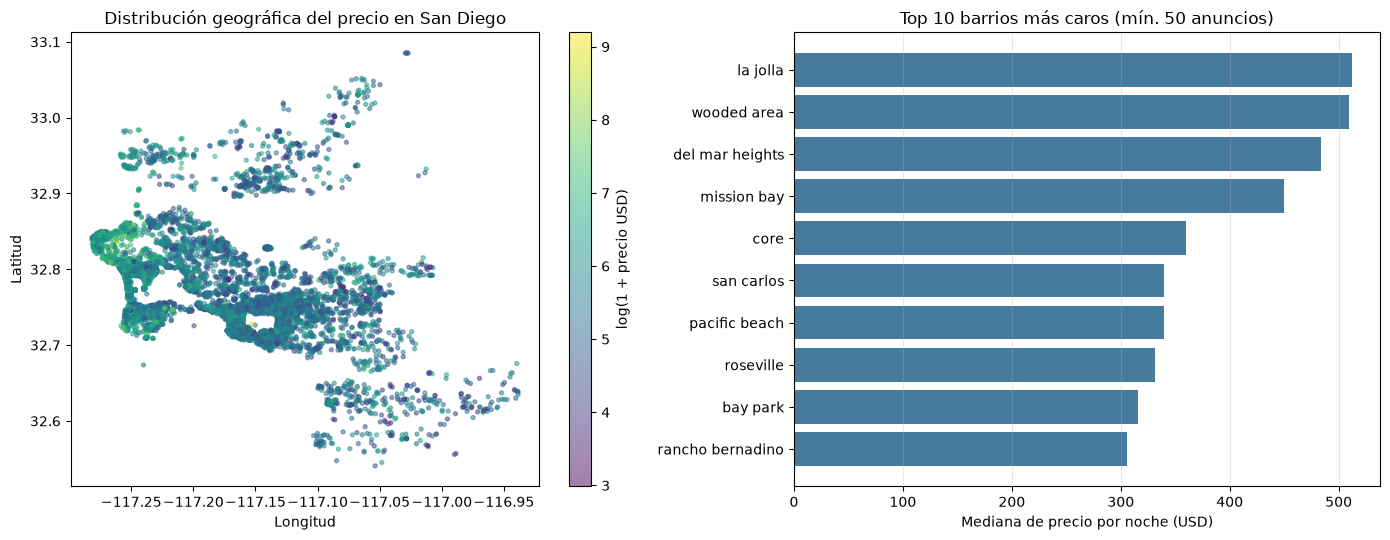

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Mapa de dispersión geográfica coloreado por log(precio)
sc = ax[0].scatter(df_precio["longitud"], df_precio["latitud"],
                   c=np.log1p(df_precio["precio_noche_usd"]),
                   cmap="viridis", s=8, alpha=0.5)
fig.colorbar(sc, ax=ax[0], label="log(1 + precio USD)")
ax[0].set_title("Distribución geográfica del precio en San Diego")
ax[0].set_xlabel("Longitud")
ax[0].set_ylabel("Latitud")

# 2. Top 10 barrios más caros (con al menos 50 anuncios para evitar sesgo por muestras pequeñas)
barrios = df_precio.groupby("barrio")["precio_noche_usd"].agg(["count", "median"])
top10_caros = barrios[barrios["count"] >= 50].sort_values("median", ascending=True).tail(10)

ax[1].barh(top10_caros.index, top10_caros["median"], color="#457b9d")
ax[1].set_title("Top 10 barrios más caros (mín. 50 anuncios)")
ax[1].set_xlabel("Mediana de precio por noche (USD)")
ax[1].grid(axis="x", alpha=0.3)

fig.tight_layout()
plt.show()

Los dos gráficos muestran que la ubicación espacial es un factor estructural del precio en San Diego, acumulandose mayores precios hacia el occidente (junto a la costa).

### Análisis multivariado: Matriz de correlación y dispersión
Identificamos qué variables numéricas y de servicios tienen mayor asociación con el precio.

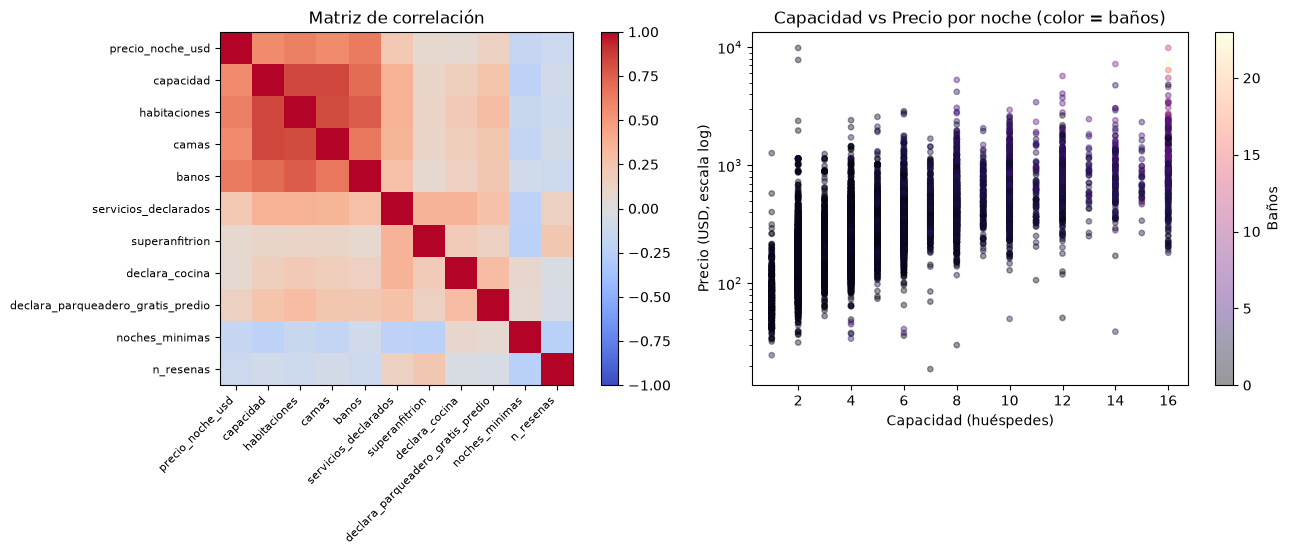

,Correlación con precio
precio_noche_usd,1.000
banos,0.635
habitaciones,0.615
capacidad,0.567
camas,0.566
servicios_declarados,0.214
declara_parqueadero_gratis_predio,0.139
superanfitrion,0.074
declara_cocina,0.061
n_resenas,-0.121


In [6]:
vars_corr = [
    "precio_noche_usd", "capacidad", "habitaciones", "camas", "banos",
    "servicios_declarados", "superanfitrion", "declara_cocina",
    "declara_parqueadero_gratis_predio", "noches_minimas", "n_resenas"
]
corr = df_precio[vars_corr].corr()

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Mapa de calor de correlaciones
im = ax[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(vars_corr)), labels=vars_corr, rotation=45, ha="right", fontsize=8)
ax[0].set_yticks(range(len(vars_corr)), labels=vars_corr, fontsize=8)
ax[0].set_title("Matriz de correlación")
fig.colorbar(im, ax=ax[0])

# 2. Dispersión: Capacidad vs Precio (coloreado por número de baños)
sc2 = ax[1].scatter(df_precio["capacidad"], df_precio["precio_noche_usd"],
                    c=df_precio["banos"], cmap="magma", alpha=0.4, s=15)
ax[1].set_yscale("log")
ax[1].set_title("Capacidad vs Precio por noche (color = baños)")
ax[1].set_xlabel("Capacidad (huéspedes)")
ax[1].set_ylabel("Precio (USD, escala log)")
fig.colorbar(sc2, ax=ax[1], label="Baños")

fig.tight_layout()
plt.show()

display(corr["precio_noche_usd"].sort_values(ascending=False).to_frame("Correlación con precio").round(3))

El analisis permite identificar tanto los mejores predictores lineales del precio como posibles riesgos de multicolinealidad